#### ▶  인공 신경망
- nn모듈 : 신경망을 구축하고 학습시키는데 필요한 모든 구성요소를 제공하는 핵심 모듈
- 주요 역할 및 구성 요소
    1. 인공 신경망 레이어(Layer) : 입력데이터를 변환하는 다양한 층을 제공
        - 선형 레이어(nn.Linear) : 완전연결층
        - 합성곱 레이어(nn.Conv2d) : 이미지 처리에 쓰이는 CNN레이어
        - 순환 레이어(nn.LTSM, nn.GRU) : 텍스트, 시계열 처리에 쓰는 RNN 레이어
    2. 활성화 함수(Activation Functions) : 비선형성을 추가하여 모델이 복잡한 패턴을 학습 할 수 있도록 해준다
        - nn.ReLU(), nn.Sigmoid(), nn.Softmax() 등
    3. 손실함수(Loss Functions) : 모델의 예측값과 실제 값의 오차를 계산
        - nn.MESLoss(), nn.CrossEntropyLoss() 등
    4. 컨테이너 : 여러 레이어를 묶어서 하나의 모델로 구조화
        - nn.Module : 모든 신경망 모델의 기본 클래스
        - 자신이 만드는 모든 커스텀 모델은 nn.Module을 상속받아 정의하여 사용
        - nn.Sequential : 레이어를 순차적으로 연결해 주는 간단한 래퍼임

In [1]:
import torch
from torch import nn
from torchviz import make_dot

Linear(in_features=1, out_features=1, bias=True)

W =  Parameter containing:
tensor([[0.2699]], requires_grad=True)
b =  Parameter containing:
tensor([-0.9478], requires_grad=True)

결과 ; tensor([-0.6779], grad_fn=<UnsafeViewBackward0>)


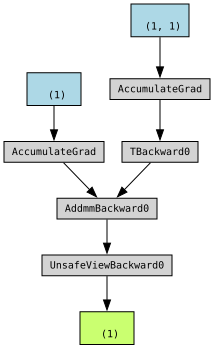

In [2]:
x = torch.tensor([1.])

model = nn.Linear(1,1)      # Linear값 하나에 출력값 하나
print(model)
print()

print('W = ', model.weight)
print('b = ', model.bias)
print()

y = model(x)
print('결과 ;', y)

# y2 = x @ model.weight + model.bias
# print('y2 :', y2)

make_dot(y)

fc1의 w =  Parameter containing:
tensor([[-0.1305],
        [-0.1171],
        [ 0.8103]], requires_grad=True)
fc1의 가중치 행렬 =  torch.Size([3, 1])
fc1의 b =  Parameter containing:
tensor([ 0.0452, -0.4167,  0.0209], requires_grad=True)
fc1의 bias size = torch.Size([3])
------------------------------
fc2의 W =  Parameter containing:
tensor([[0.5626, 0.4087, 0.3546]], requires_grad=True)
fc2의 b =  Parameter containing:
tensor([0.4766], requires_grad=True)
------------------------------
tensor([-0.0854, -0.5338,  0.8312], grad_fn=<UnsafeViewBackward0>)
tensor([0.5051], grad_fn=<UnsafeViewBackward0>)
------------------------------
tensor([0.5051], grad_fn=<AddBackward0>)


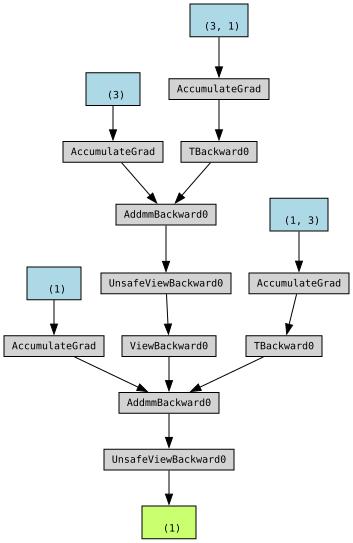

In [14]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

print('fc1의 w = ', fc1.weight)
print('fc1의 가중치 행렬 = ', fc1.weight.shape)
# W.shape = (out_features, in_features)

print('fc1의 b = ', fc1.bias)
print('fc1의 bias size =', fc1.bias.shape)
print('-'*30)

print('fc2의 W = ',fc2.weight)
print('fc2의 b = ',fc2.bias)
print('-'*30)

x = torch.tensor([1.])
x = fc1(x)
print(x)
y = fc2(x)
print(y)
print('-'*30)

x = torch.tensor([1.])
y2 = (x @ fc1.weight.T + fc1.bias) @ fc2.weight.T + fc2.bias
print(y2)

make_dot(y)

Feature과 Channel의 차이
|구분|Feature|Channel|
|:---:|:---:|:---:|
|의미|데이터가 가진 특성 또는 변수|데이터의 독립적인 데이터 경로 또는 구성요소|
|에시|나이, 키, 몸무게|RGB 이미지의 R, G, B|
|주로 사용하는 곳|일반적인 데이터, 머신러닝, 완전연결층|이미지처리, CNN, 신호처리|

tensor([ 0.1893, -0.6204])
tensor([ 0.8170, -0.1259,  0.2326], grad_fn=<UnsafeViewBackward0>)


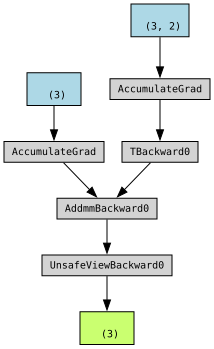

In [17]:
model = nn.Linear(2,3)      # 2개의 채널(or feature)를 가진 데이터에 대해 3개의 채널(or feature)을 가지는 데이터로 변환하는 것
x = torch.randn(2)
print(x)
print(model(x))

make_dot(model(x))

tensor([[-0.2080,  0.1337],
        [-1.2418,  0.0426],
        [ 1.0322, -0.1166],
        [ 1.4160, -1.8869],
        [ 0.3274, -0.0418]])
tensor([[-0.5460, -0.2953, -0.6372],
        [ 0.1784, -0.9768, -0.8913],
        [-1.4115,  0.6323, -0.4193],
        [-1.6621,  1.4365, -0.7613],
        [-0.9190,  0.1258, -0.5594]], grad_fn=<AddmmBackward0>)
torch.Size([5, 3])
torch.Size([4, 5, 3])
torch.Size([2, 3, 6, 5, 3, 3])


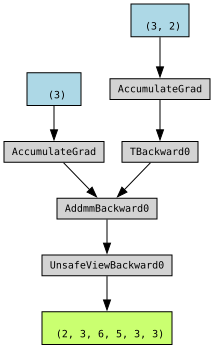

In [24]:
model = nn.Linear(2,3)

x = torch.randn(5,2)        # 2개의 특징(몸무게, 키)을 가지는 데이터(사람) 5개(명)

print(x)
print(model(x))
model_x = model(x)
print(model_x.shape)

x = torch.randn(4,5,2)
print(model(x).shape)

x = torch.randn(2,3,6,5,3,2)
print(model(x).shape)

make_dot(model(x))

In [25]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

x = torch.tensor([1.])
x = fc1(x)
y = fc2(x)

model=nn.Sequential(fc1, fc2)
x = torch.tensor([1.])
print(model(x))


tensor([-0.3271], grad_fn=<UnsafeViewBackward0>)


In [26]:
model = nn.Sequential(nn.Linear(2,5),
                      nn.Linear(5,10),
                      nn.Linear(10,3))

x = torch.randn(5,2)
print(model(x))


tensor([[-0.1189,  0.4852, -0.0780],
        [-0.1876,  0.5932, -0.3319],
        [-0.2184,  0.3875,  0.0374],
        [ 0.0232,  0.5904, -0.1775],
        [-0.1329,  0.2432,  0.3724]], grad_fn=<AddmmBackward0>)
